# Descrição do Problema

O problema abordado neste projeto consiste na **previsão da aprovação de empréstimos bancários**, com base em informações financeiras e demográficas dos solicitantes.

> Uma decisão incorreta na avaliação de crédito pode gerar:

- Prejuízos financeiros (inadimplência)
- Aumento do risco de crédito
- Impacto negativo na carteira de crédito

> O objetivo é desenvolver um modelo de **classificação binária** capaz de prever se um empréstimo será:

- **Aprovado (1)**
- **Negado (0)**


A previsão é feita com base em variáveis como renda anual, pontuação de crédito, número de dependentes e situação de emprego.

# Origem e Coleta dos Dados

O dataset utilizado é o **Loan Approval Dataset**, disponível publicamente na plataforma Kaggle.

Trata-se de um conjunto de dados sintético contendo informações de aproximadamente **1.000 solicitantes de empréstimo**.

>Segundo a descrição disponibilizada na plataforma:

- Os dados foram gerados para fins educacionais
- Não representam clientes reais
- Foram estruturados para simular um cenário de análise de risco de crédito

>Como se trata de dados sintéticos:

- Não há datas específicas de coleta
- O processo gerador dos dados foi artificial, provavelmente baseado em distribuições estatísticas que simulam perfis financeiros reais.

In [1]:
# Bibliotecas Numéricas e Dados
import numpy as np
import pandas as pd


# Visualização de Dados
import matplotlib.pyplot as plt
import seaborn as sns


# Machine Learning - Modelos
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier


# Machine Learning - Avaliação
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score
from sklearn.metrics import confusion_matrix


# Machine Learning - Model Selection
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV


# Visualização de Árvores
import graphviz


# Dataset (Kaggle)
import kagglehub
from kagglehub import KaggleDatasetAdapter

/Users/souzart/Supervised_Learning_Model/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/souzart/Supervised_Learning_Model/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#Importandando o Dataset

file_path = "loanapproval.csv"

df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "amineipad/loan-approval-dataset",
    file_path
)

/var/folders/dy/x8lddh157g95jwstklym7kkh0000gn/T/ipykernel_2829/4136975201.py:5: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


In [3]:
df.to_csv("loanapproval.csv", index=False)

# Unidade de Observação

A unidade de observação do dataset é:

> **Cada linha representa um solicitante de empréstimo.**

Cada registro contém as características individuais de um candidato ao crédito, juntamente com o resultado da análise (aprovação ou não).

In [4]:
df.head(5)

,applicant_id,age,gender,marital_status,annual_income,loan_amount,credit_score,num_dependents,existing_loans_count,employment_status,loan_approved
0,1,59,Male,Divorced,100073,7169,793,1,1,Unemployed,1
1,2,49,Male,Married,112197,23556,789,0,2,Employed,1
2,3,35,Male,Divorced,84429,27052,372,1,4,Unemployed,0
3,4,63,Female,Single,124195,11313,808,3,4,Self-employed,1
4,5,28,Female,Married,81627,13315,689,0,1,Unemployed,1


## Inspeção Inicial da Base de Dados

Antes de iniciar a análise exploratória e a modelagem, será realizada uma verificação estrutural do dataset. Essa etapa permite compreender a dimensão da base, identificar possíveis valores ausentes e verificar os tipos de dados das variáveis.

> Para isso, serão utilizados os seguintes comandos:

- `df.shape()`  
  Permite identificar o número de linhas e colunas da base de dados.

- `df.isnull().sum()`  
  Verifica a quantidade de valores ausentes em cada coluna.

- `df.info()`  
  Fornece informações detalhadas sobre os tipos de dados, quantidade de valores não nulos e estrutura geral do dataset.

In [5]:
df.shape

(1000, 11)

In [6]:
df.isnull().sum()

applicant_id            0
age                     0
gender                  0
marital_status          0
annual_income           0
loan_amount             0
credit_score            0
num_dependents          0
existing_loans_count    0
employment_status       0
loan_approved           0
dtype: int64

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   applicant_id          1000 non-null   int64 
 1   age                   1000 non-null   int64 
 2   gender                1000 non-null   object
 3   marital_status        1000 non-null   object
 4   annual_income         1000 non-null   int64 
 5   loan_amount           1000 non-null   int64 
 6   credit_score          1000 non-null   int64 
 7   num_dependents        1000 non-null   int64 
 8   existing_loans_count  1000 non-null   int64 
 9   employment_status     1000 non-null   object
 10  loan_approved         1000 non-null   int64 
dtypes: int64(8), object(3)
memory usage: 86.1+ KB


In [8]:
print(f'Variáveis duplicadas: {df.duplicated().sum()}')

print(f'\nId duplicados: {df.duplicated(subset="applicant_id").sum()}')

Variáveis duplicadas: 0

Id duplicados: 0


### Verificação de Registros Duplicados

Além da verificação de valores ausentes, também foi realizada a análise de registros duplicados no conjunto de dados.

Primeiramente foi utilizada a função `duplicated()` para identificar possíveis linhas repetidas no dataset. Em seguida, foi feita uma verificação específica da variável `applicant_id`, que representa o identificador único de cada solicitante.

> Os resultados indicaram que não há registros duplicados no conjunto de dados, o que sugere que cada observação representa uma aplicação de crédito distinta. Dessa forma, não foi necessário realizar remoção de registros nesta etapa de limpeza.

# Visualização de Variáveis Categóricas (Qualitativas)

Nesta etapa são analisadas as variáveis categóricas do conjunto de dados, como `gender`, `marital_status` e `employment_status`.

A visualização é realizada por meio de gráficos de barras (countplot), que permitem observar a frequência de cada categoria presente no dataset.  

> Com esta análise, podemos:

- Identificar a distribuição das categorias  
- Detectar possíveis desbalanceamentos  
- Entender o perfil predominante dos solicitantes

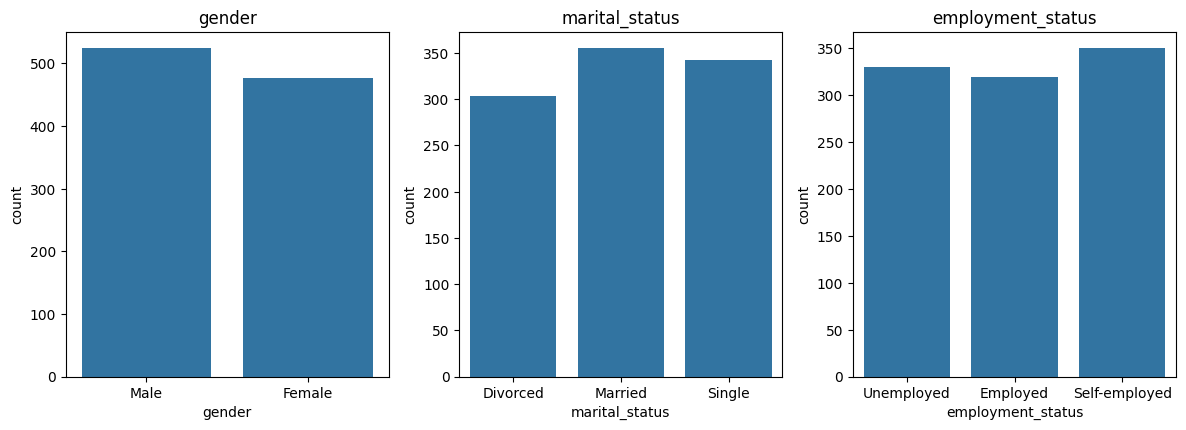

In [9]:
column_name = ['gender', 'marital_status', 'employment_status']

plt.figure(figsize=(12, 8))
for idx, i in enumerate(column_name, 1):

    plt.subplot(2, 3, idx)
    sns.countplot(x= i, data= df)
    plt.title(i)


plt.tight_layout()
plt.show()

## Engenharia de Variáveis (Feature Engineering)

Nesta etapa, as variáveis categóricas do conjunto de dados foram transformadas em variáveis numéricas para possibilitar sua utilização posterior no modelo.

Algoritmos de classificação, como árvores de decisão, não operam diretamente com dados categóricos em formato textual. Por esse motivo, é necessário converter essas variáveis para representações numéricas.

> Neste projeto foi utilizado o método de mapeamento ordinal, no qual cada categoria recebe um valor numérico específico.

As seguintes variáveis categóricas foram convertidas:

- **gender**: Male = 0, Female = 1  
- **marital_status**: Single = 0, Married = 1, Divorced = 2  
- **employment_status**: Unemployed = 0, Employed = 1, Self-employed = 2  

Essa abordagem foi adotada por ser simples e adequada para modelos baseados em árvores, como o **Decision Tree Classifier**, que conseguem lidar bem com esse tipo de representação numérica.

In [10]:
df['gender'].unique()

array(['Male', 'Female'], dtype=object)

In [11]:
df['gender'] = df['gender'].map({'Male': 0,
                                 'Female': 1})

In [12]:
df['marital_status'].unique()

array(['Divorced', 'Married', 'Single'], dtype=object)

In [13]:
df['marital_status'] = df['marital_status'].map({'Single': 0,
                                                 'Married': 1,
                                                 'Divorced': 2})

In [14]:
df['employment_status'].unique()

array(['Unemployed', 'Employed', 'Self-employed'], dtype=object)

In [15]:
df['employment_status'] = df['employment_status'].map({'Unemployed': 0,
                                                       'Employed': 1,
                                                       'Self-employed': 2})

## Variáveis Dummy

Uma alternativa comum para tratar variáveis categóricas é a criação de **variáveis dummy**, onde cada categoria é representada por uma variável binária.

Essa abordagem é frequentemente utilizada em modelos lineares, como regressão logística.

Neste projeto, optou-se pelo mapeamento ordinal por dois motivos:

1. O modelo utilizado (árvore de decisão) consegue lidar adequadamente com variáveis categóricas convertidas em valores numéricos.
2. O mapeamento reduz a dimensionalidade do conjunto de dados em comparação com a criação de múltiplas variáveis dummy.

Ainda assim, a criação de variáveis dummy foi realizada como alternativa metodológica.

In [16]:
df_dummies = pd.get_dummies(df, columns=["gender", "marital_status", "employment_status"], drop_first=True)

df_dummies.head()

,applicant_id,age,annual_income,loan_amount,credit_score,num_dependents,existing_loans_count,loan_approved,gender_1,marital_status_1,marital_status_2,employment_status_1,employment_status_2
0,1,59,100073,7169,793,1,1,1,False,False,True,False,False
1,2,49,112197,23556,789,0,2,1,False,True,False,True,False
2,3,35,84429,27052,372,1,4,0,False,False,True,False,False
3,4,63,124195,11313,808,3,4,1,True,False,False,False,True
4,5,28,81627,13315,689,0,1,1,True,True,False,False,False


# Visualização de Variáveis Numéricas (Quantitativas)

Nesta etapa são analisadas as variáveis numéricas do dataset.

> Serão utilizados gráficos como histogramas e boxplots para avaliar:

- Distribuição dos valores  
- Presença de assimetrias  
- Possíveis outliers  
- Tendências centrais (média e mediana)

In [17]:
df.describe().round(2)

,applicant_id,age,gender,marital_status,annual_income,loan_amount,credit_score,num_dependents,existing_loans_count,employment_status,loan_approved
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,500.50,42.52,0.48,0.96,81972.97,27244.87,576.12,1.98,2.04,1.02,0.73
std,288.82,12.61,0.50,0.80,37547.26,12822.75,155.92,1.42,1.41,0.82,0.44
min,1.00,21.00,0.00,0.00,20155.00,5082.00,300.00,0.00,0.00,0.00,0.00
25%,250.75,32.00,0.00,0.00,48913.25,16587.50,443.75,1.00,1.00,0.00,0.00
50%,500.50,43.00,0.00,1.00,82050.00,27041.50,573.50,2.00,2.00,1.00,1.00
75%,750.25,53.00,1.00,2.00,113556.00,37939.25,713.25,3.00,3.00,2.00,1.00
max,1000.00,64.00,1.00,2.00,149951.00,49864.00,849.00,4.00,4.00,2.00,1.00


## Histogramas

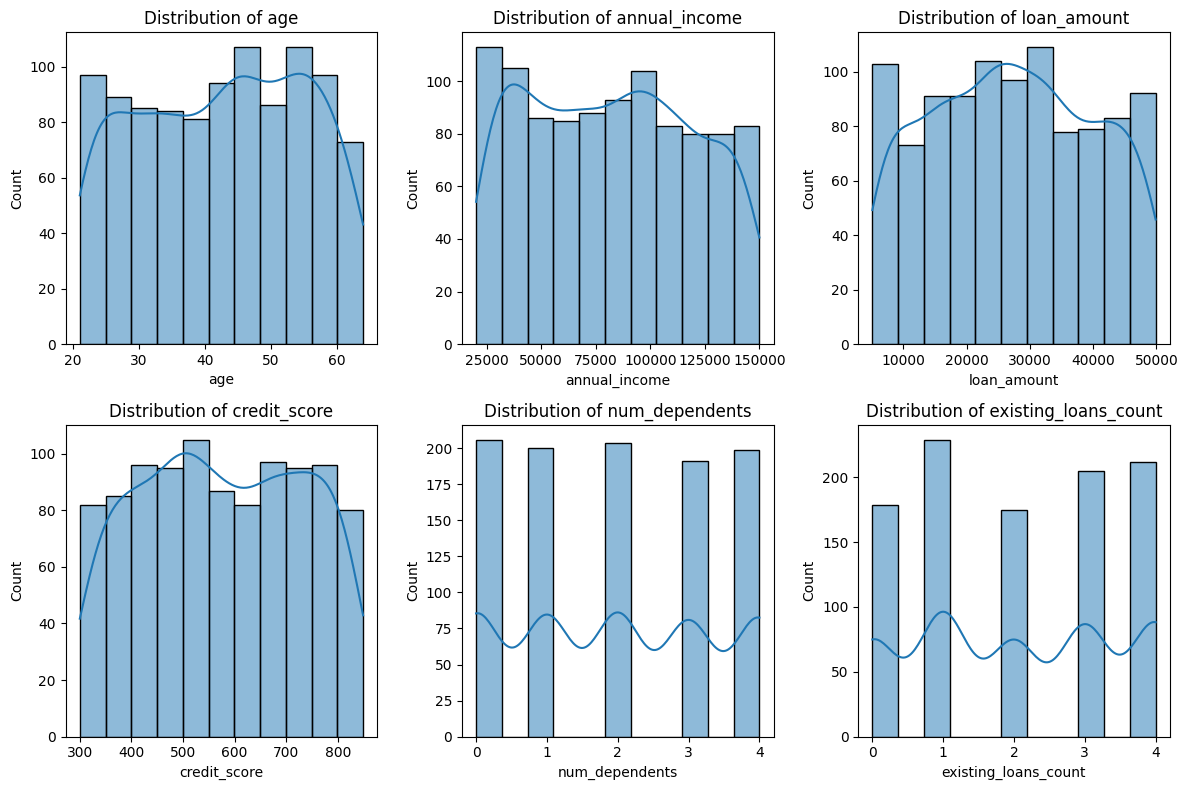

In [18]:
numerical_cols = ['age', 'annual_income', 'loan_amount',
                  'credit_score', 'num_dependents', 'existing_loans_count']

plt.figure(figsize=(12, 8))

for i, col in enumerate(numerical_cols):
    plt.subplot(2, 3, i+1)
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')

plt.tight_layout()
plt.show()


### Interpretação das Variáveis `num_dependents` e `existing_loans_count`

As variáveis `num_dependents` (número de dependentes) e `existing_loans_count` (quantidade de empréstimos existentes) são variáveis **discretas**, compostas por valores inteiros pequenos (0 a 4).

> Ao utilizar histogramas com curva KDE para visualizá-las, observa-se um comportamento “ondulado” na linha de densidade. Isso ocorre porque:

- A curva KDE (Kernel Density Estimation) tenta estimar uma distribuição contínua;
- Como essas variáveis possuem poucos valores possíveis, a curva gerada não representa uma distribuição contínua real.

A análise indica que ambas as variáveis apresentam distribuição relativamente uniforme entre os valores possíveis, o que sugere ausência de forte concentração em uma única categoria.


## Boxplot

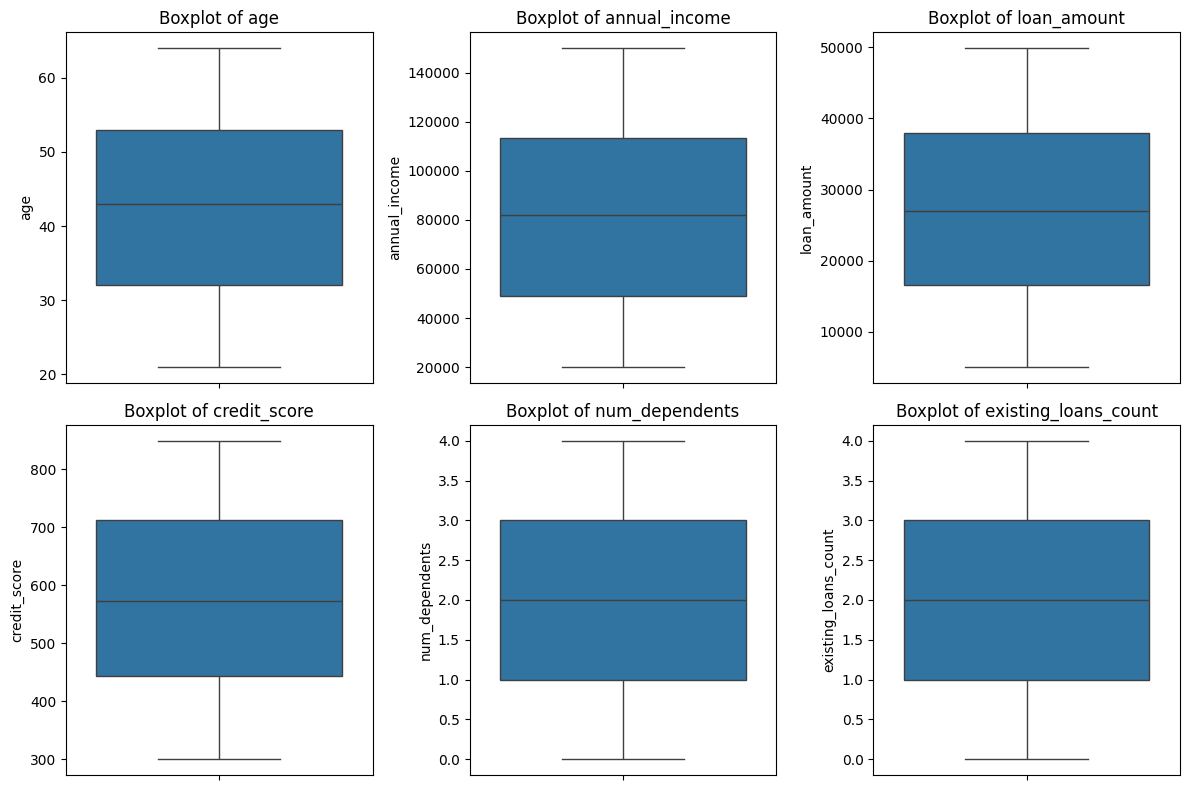

In [19]:
plt.figure(figsize=(12, 8))

for i, col in enumerate(numerical_cols):
    plt.subplot(2, 3, i+1)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()


# Análise Exploratória Orientada ao Modelo de Machine Learning

Nesta etapa, a análise passa a ter foco na modelagem preditiva. O objetivo agora é verificar como algumas variáveis explicativas se relacionam com a variável target (`loan_approved`) e identificar padrões que possam ser úteis para o modelo.

Para isso, será realizada a categorização de uma variável numérica utilizando as funções `cut` e `qcut`. Ao transformar a variável contínua em faixas, será possível comparar a taxa de aprovação em cada grupo e avaliar se existem diferenças claras no comportamento da target.

> A estratégia adotada consiste em:

- Agrupar a variável selecionada em categorias;
- Calcular a taxa média de aprovação (`loan_approved`) em cada grupo;
- Avaliar se há separação clara entre os grupos quanto ao comportamento da target;
- Identificar variações relevantes na taxa do evento que indiquem potencial poder preditivo.

> A questão orientadora desta etapa é:

**A variável categorizada parece separar grupos com comportamentos distintos da target?**

Além disso, será realizada uma comparação entre as abordagens `cut` (segmentação baseada em critérios substantivos) e `qcut` (segmentação baseada na distribuição dos dados), discutindo qual estratégia produz uma segmentação mais informativa para fins preditivos.

A partir dessa análise, espera-se identificar evidências sobre o potencial explicativo da variável estudada e sua utilidade na construção do modelo de classificação.


## Heatmap de correlação (visão geral)

In [20]:
df_analysis = df.copy()

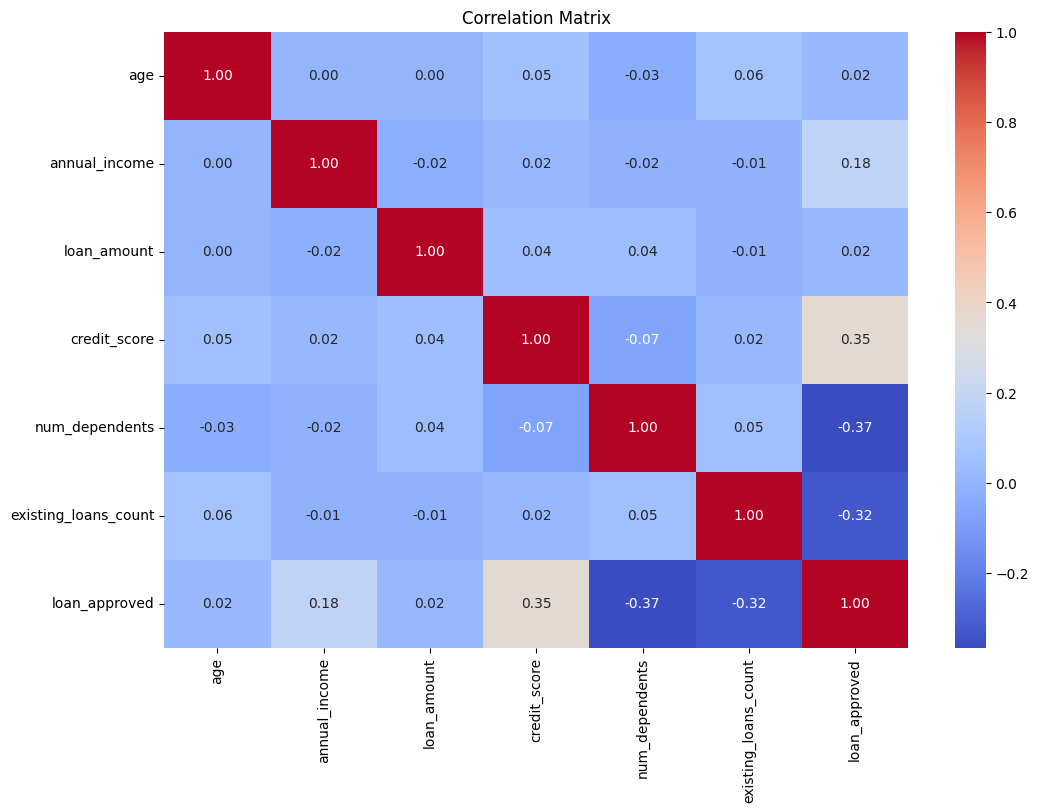

In [21]:
plt.figure(figsize=(12,8))
sns.heatmap(df[numerical_cols + ['loan_approved']].corr(),
            annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()


## Análise com `cut`

Na segmentação por faixas predefinidas, observou-se um aumento expressivo na taxa de aprovação conforme o score de crédito aumenta. Solicitantes com score muito baixo apresentaram taxa de aprovação próxima de 56%, enquanto aqueles classificados nas faixas mais altas superaram 90% de aprovação.

Essa diferença significativa entre os grupos indica que o `credit_score` possui forte capacidade de discriminar o comportamento da variável target. Apesar de uma pequena variação entre as categorias mais altas, o padrão geral é de crescimento consistente na taxa de aprovação conforme melhora a pontuação de crédito.

In [22]:
df['score_cut'] =pd.cut(
        df['credit_score'],
        bins=[300, 580, 670, 740, 800, 850],
        labels=['Muito Baixo', 'Baixo', 'Médio', 'Bom', 'Excelente'])

taxa_cut = df.groupby('score_cut')['loan_approved'].mean()

print(taxa_cut)

score_cut
Muito Baixo    0.567515
Baixo          0.852761
Médio          0.897638
Bom            0.941176
Excelente      0.924051
Name: loan_approved, dtype: float64


/var/folders/dy/x8lddh157g95jwstklym7kkh0000gn/T/ipykernel_2829/4207684718.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  taxa_cut = df.groupby('score_cut')['loan_approved'].mean()


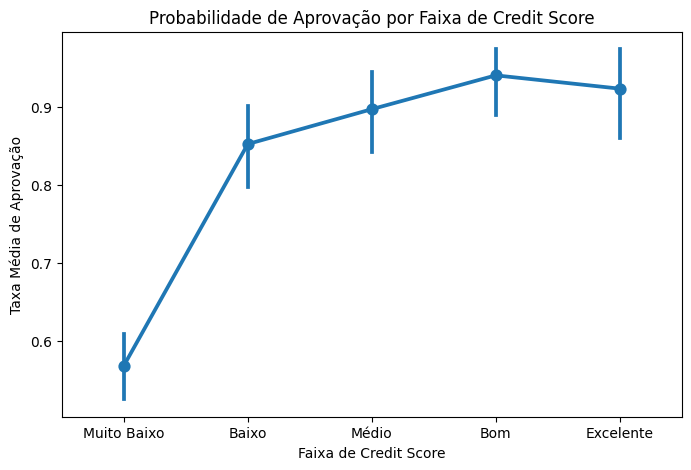

In [23]:
plt.figure(figsize=(8,5))

sns.pointplot(
    x='score_cut',
    y='loan_approved',
    data=df,
    errorbar=('ci',95)
)

plt.title('Probabilidade de Aprovação por Faixa de Credit Score')
plt.xlabel('Faixa de Credit Score')
plt.ylabel('Taxa Média de Aprovação')

plt.show()

## Análise com `qcut`

Ao utilizar `qcut`, a variável foi dividida em grupos com tamanhos semelhantes. Nesse caso, a separação entre os grupos ficou ainda mais evidente, apresentando um padrão monotônico crescente: os dois primeiros grupos (scores mais baixos) apresentaram taxas de aprovação próximas de 55–59%, enquanto os dois últimos grupos (scores mais altos) apresentaram taxas superiores a 85%, chegando a aproximadamente 92%.

Essa segmentação evidencia uma divisão clara entre perfis de maior e menor probabilidade de aprovação, reforçando o alto poder preditivo da variável.

In [24]:
df['score_qcut'] = pd.qcut(df['credit_score'], q=4)

taxa_qcut = df.groupby('score_qcut')['loan_approved'].mean()
print(taxa_qcut)


score_qcut
(299.999, 443.75]    0.548
(443.75, 573.5]      0.588
(573.5, 713.25]      0.856
(713.25, 849.0]      0.924
Name: loan_approved, dtype: float64


/var/folders/dy/x8lddh157g95jwstklym7kkh0000gn/T/ipykernel_2829/1608253427.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  taxa_qcut = df.groupby('score_qcut')['loan_approved'].mean()


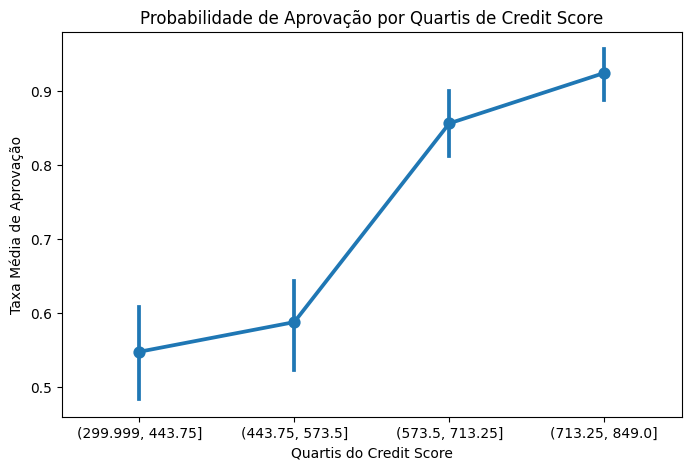

In [25]:
plt.figure(figsize=(8,5))

sns.pointplot(
    x='score_qcut',
    y='loan_approved',
    data=df,
    errorbar=('ci',95)
)

plt.title('Probabilidade de Aprovação por Quartis de Credit Score')
plt.xlabel('Quartis do Credit Score')
plt.ylabel('Taxa Média de Aprovação')

plt.show()

## Comparação entre as estratégias

O gráfico apresenta a probabilidade média de aprovação para cada faixa de credit score.

* Os intervalos de confiança indicam a incerteza da estimativa da média.

* Observa-se que faixas mais altas de score apresentam probabilidade significativamente maior de aprovação de crédito.

> De modo geral, ambas as abordagens indicam que o `credit_score` é uma variável fortemente associada à aprovação do empréstimo.


## Associação entre `credit_score` e `loan_approved`

In [26]:
df.groupby('score_cut')['loan_approved'] \
  .agg(['mean', 'count']) \
  .sort_values('count', ascending=True)

/var/folders/dy/x8lddh157g95jwstklym7kkh0000gn/T/ipykernel_2829/3281510713.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('score_cut')['loan_approved'] \


,mean,count
score_cut,,
Excelente,0.924051,79
Bom,0.941176,119
Médio,0.897638,127
Baixo,0.852761,163
Muito Baixo,0.567515,511


In [27]:
df.groupby('score_qcut')['loan_approved'] \
  .agg(['mean', 'count']) \
  .sort_values('mean', ascending=False)


/var/folders/dy/x8lddh157g95jwstklym7kkh0000gn/T/ipykernel_2829/553481212.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('score_qcut')['loan_approved'] \


,mean,count
score_qcut,,
"(713.25, 849.0]",0.924,250
"(573.5, 713.25]",0.856,250
"(443.75, 573.5]",0.588,250
"(299.999, 443.75]",0.548,250


Observa-se que **quanto maior o score, maior a taxa de aprovação**. O grupo com score “Muito Baixo” apresenta taxa de aprovação significativamente inferior (~56,8%) em comparação às demais faixas (acima de 85%).

Na análise por quartis (`score_qcut`), o padrão se confirma de maneira ainda mais clara: a taxa de aprovação varia de 54,8% no quartil inferior para 92,4% no quartil superior, com todos os grupos apresentando o mesmo tamanho (n=250). Isso reforça a estabilidade do comportamento identificado.

Também é possível notar que a principal mudança ocorre nas faixas intermediárias, indicando que o efeito do score não é perfeitamente linear, mas apresenta um comportamento mais acentuado a partir de determinados níveis (efeito de limiar).

Dessa forma, `credit_score` se destaca como uma das variáveis mais promissoras para o modelo, apresentando forte capacidade de discriminação entre clientes com maior e menor probabilidade de aprovação.


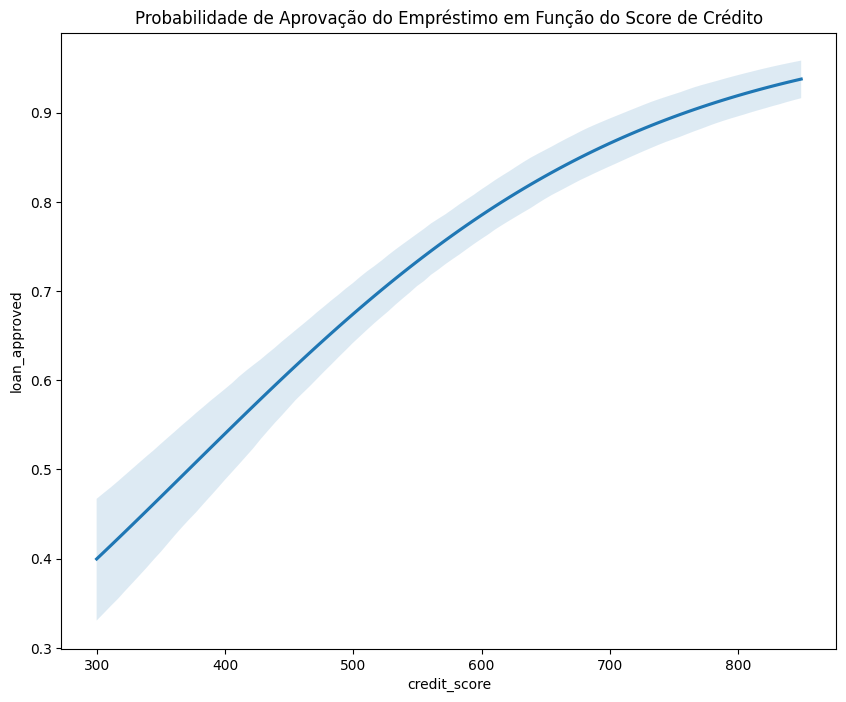

In [28]:
plt.rc('figure', figsize=(10, 8))

sns.regplot(
    x='credit_score',
    y='loan_approved',
    data=df,
    logistic=True,
    scatter=False)

plt.title('Probabilidade de Aprovação do Empréstimo em Função do Score de Crédito')

plt.show()

O gráfico apresenta a relação entre o score de crédito (credit_score) e a probabilidade de aprovação do empréstimo (loan_approved).

> A curva logística indica que quanto maior o score de crédito, maior é a probabilidade de aprovação do empréstimo. Observa-se que clientes com scores mais baixos (próximos de 300) possuem menor chance de aprovação, enquanto clientes com scores mais altos (acima de 700) apresentam uma probabilidade significativamente maior de terem o empréstimo aprovado.

A faixa sombreada ao redor da curva representa o intervalo de confiança da estimativa, indicando o grau de incerteza da relação estimada entre as variáveis.

##Definição de Variáveis e Teste do Modelo

Nesta etapa são definidas as variáveis explicativas (X) e a variável alvo (y) que serão utilizadas no treinamento do modelo de Machine Learning.

> y (variável alvo): corresponde à coluna loan_approved, que representa o resultado que o modelo deve prever (se o empréstimo foi aprovado ou não).

> x (variáveis preditoras): contém as demais características dos solicitantes que podem influenciar a decisão de aprovação do empréstimo.

Algumas colunas foram removidas utilizando drop():
* applicant_id: é apenas um identificador único do cliente e não possui informação relevante para a previsão do modelo.

* loan_approved: foi removida de X porque ela é a variável alvo (y). Mantê-la nas variáveis preditoras causaria data leakage, permitindo que o modelo "veja" a resposta correta durante o treinamento.

Dessa forma, o modelo utiliza apenas as variáveis relevantes para aprender os padrões que influenciam a aprovação de crédito.

In [29]:
x = df_analysis.drop(['applicant_id','loan_approved'], axis = 1)
y = df_analysis['loan_approved']

In [30]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.3, random_state=42)

In [31]:
param_grid = {'max_depth': [1,2,3,4,5,6,7,8,9,10]}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy')

grid.fit(x_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42),
             param_grid={'max_depth': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]},
             scoring='accuracy')

In [32]:
clf = grid.best_estimator_


clf

DecisionTreeClassifier(max_depth=7, random_state=42)

In [33]:
pred = clf.predict(x_test)

accuracy = accuracy_score(y_test, pred)
print("Accuracy:", accuracy)

Accuracy: 0.9666666666666667


In [34]:
confusion_matrix(y_test, pred)

array([[ 74,   7],
       [  3, 216]])

In [35]:
print("Accuracy:", accuracy_score(y_test, pred))

print("\nClassification Report:\n")
print(classification_report(y_test, pred))

Accuracy: 0.9666666666666667

Classification Report:

              precision    recall  f1-score   support

           0       0.96      0.91      0.94        81
           1       0.97      0.99      0.98       219

    accuracy                           0.97       300
   macro avg       0.96      0.95      0.96       300
weighted avg       0.97      0.97      0.97       300



In [36]:
pd.Series(
    clf.feature_importances_,
    index=x.columns
).sort_values(ascending=False)

credit_score            0.266014
existing_loans_count    0.198945
num_dependents          0.193855
employment_status       0.189261
annual_income           0.138380
marital_status          0.013545
age                     0.000000
gender                  0.000000
loan_amount             0.000000
dtype: float64

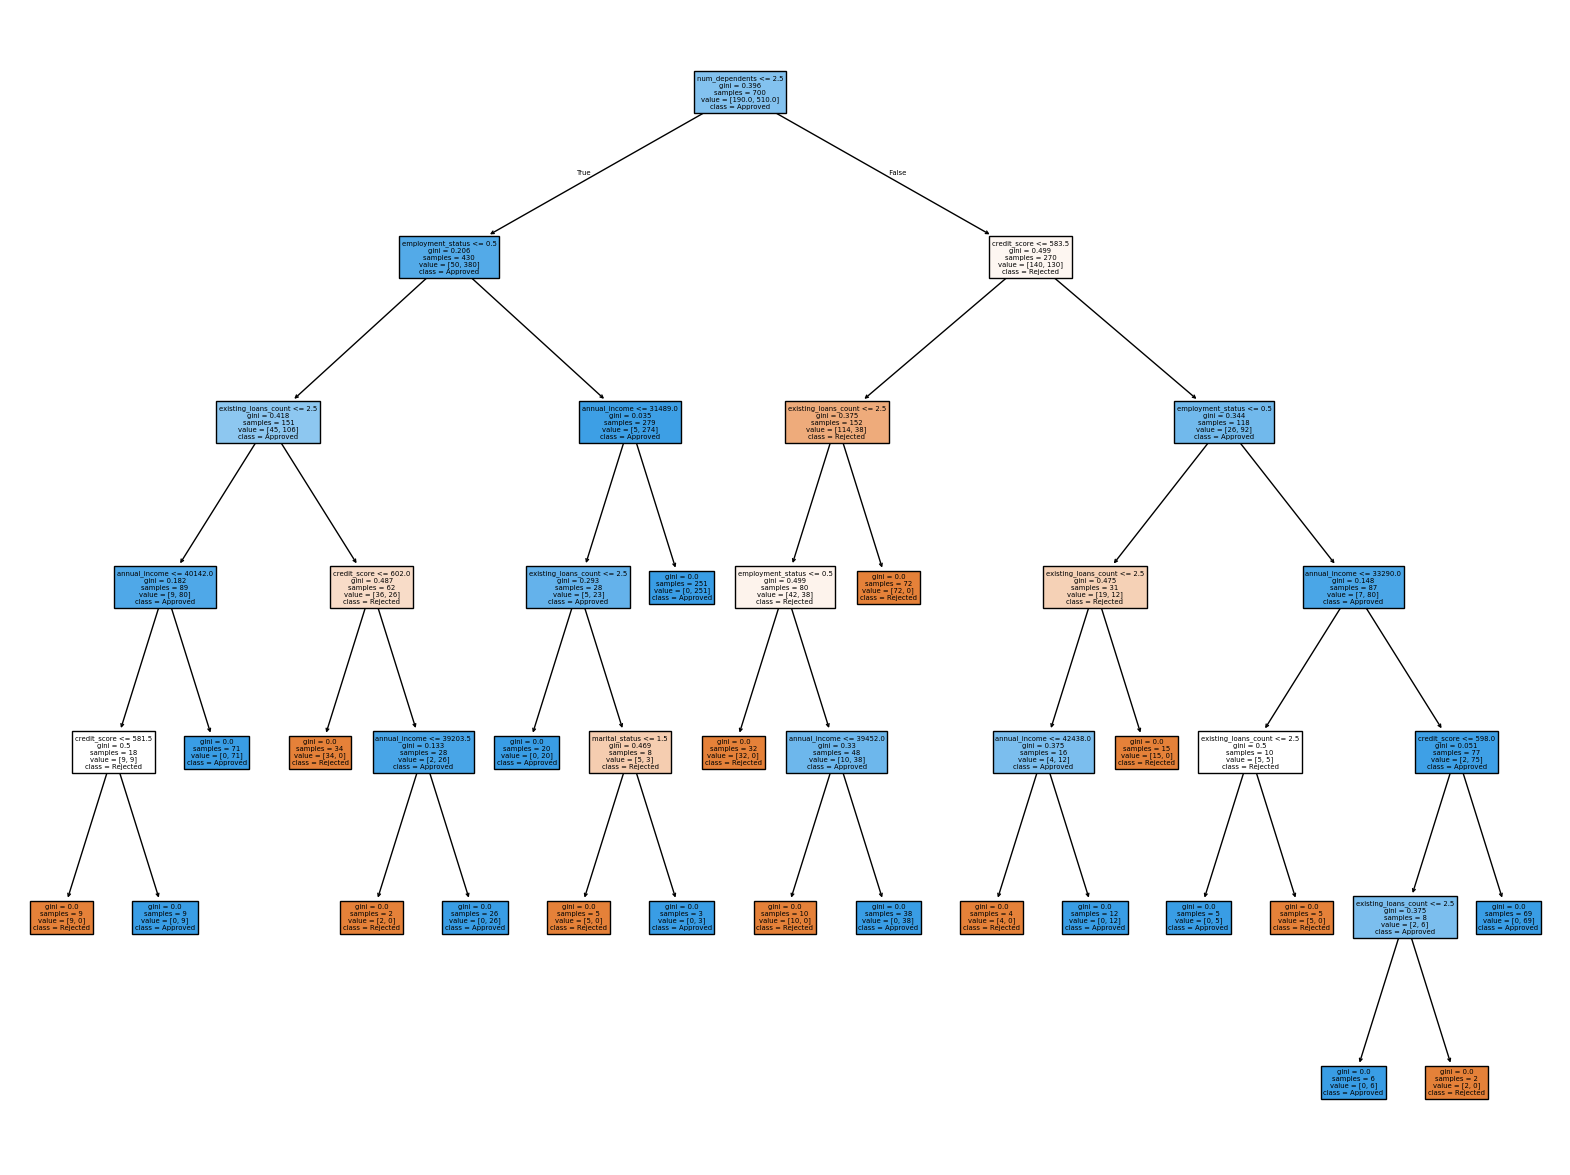

In [37]:
plt.figure(figsize=(20,15))

tree.plot_tree(
    clf,
    feature_names=x.columns,
    class_names=['Rejected','Approved'],
    filled=True);

O modelo apresentou uma accuracy de aproximadamente 96,7% no conjunto de teste. A matriz de confusão indica que o modelo classificou corretamente a grande maioria dos casos, com 74 rejeições corretas e 216 aprovações corretas, totalizando 290 previsões corretas em 300 observações.

> Os erros foram relativamente poucos, com 7 casos em que o modelo aprovou um empréstimo que deveria ser rejeitado e 3 casos em que o modelo rejeitou um empréstimo que poderia ser aprovado.

## Avaliação adicional do modelo usando AUC e Gini

In [39]:
y_prob = clf.predict_proba(x_test)[:,1]

# AUC
auc = roc_auc_score(y_test, y_prob)

# Gini
gini = 2*auc - 1


pd.DataFrame({
    "Métrica": ["AUC", "Gini"],
    "Valor": [auc, gini]
}).style.hide(axis="index")

Métrica,Valor
AUC,0.949941
Gini,0.899882


### Avaliação do Modelo com AUC e Coeficiente de Gini

Além das métricas tradicionais de classificação, foi calculada a **AUC (Area Under the ROC Curve)** e o **coeficiente de Gini**.

* A AUC obtida foi aproximadamente **0.95**, indicando que o modelo possui excelente capacidade de distinguir entre aplicações aprovadas e não aprovadas.

* O coeficiente de Gini, resultou em aproximadamente **0.90**. Valores elevados como este, indicam maior capacidade discriminatória do modelo.

Esses resultados sugerem que o modelo apresenta forte poder preditivo na separação entre as classes de aprovação de empréstimo.

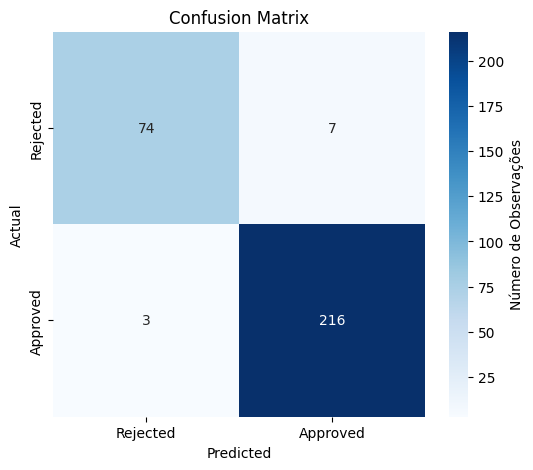

In [40]:
cm = confusion_matrix(y_test, pred)

plt.figure(figsize=(6,5))

ax = sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Rejected','Approved'],
    yticklabels=['Rejected','Approved'],
    cbar=True)


cbar = ax.collections[0].colorbar
cbar.set_label('Número de Observações')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

> De forma geral, a matriz de confusão demonstra que o modelo possui alto desempenho, com a grande maioria das previsões sendo classificadas corretamente e apenas um pequeno número de erros no conjunto de teste.

In [41]:
# Previsões do modelo
y_pred = clf.predict(x_test)


df_test = x_test.copy()

df_test["real"] = y_test
df_test["predito"] = y_pred
df_test["score"] = x_test["credit_score"]


df_test["faixa_score"] = pd.cut(
    df_test["score"],
    bins=[300,580,670,740,800,850],
    labels=["Muito Baixo","Baixo","Médio","Bom","Excelente"])


avaliacao_score = df_test.groupby("faixa_score")[["real","predito"]].mean()

avaliacao_score

/var/folders/dy/x8lddh157g95jwstklym7kkh0000gn/T/ipykernel_2829/107641302.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avaliacao_score = df_test.groupby("faixa_score")[["real","predito"]].mean()


,real,predito
faixa_score,,
Muito Baixo,0.552448,0.573427
Baixo,0.808511,0.829787
Médio,0.930233,0.953488
Bom,0.933333,0.911111
Excelente,0.909091,0.909091


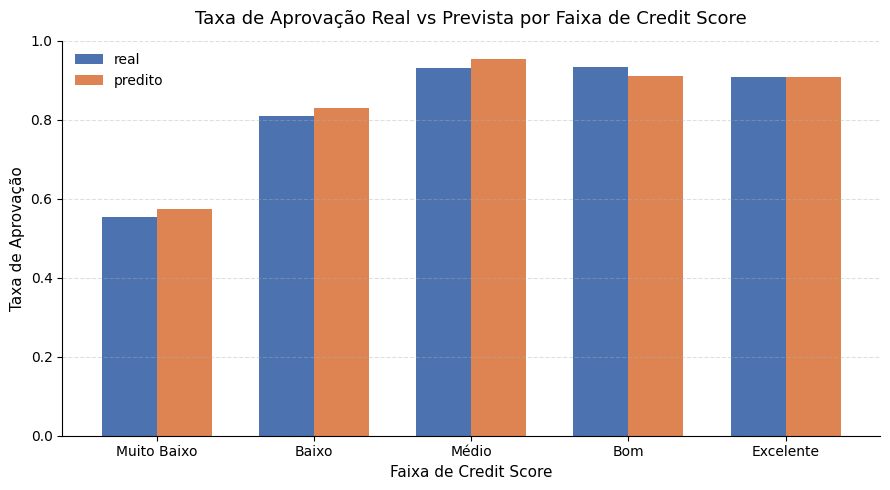

In [42]:
fig, ax = plt.subplots(figsize=(9,5))

avaliacao_score.plot(
    kind="bar",
    ax=ax,
    color=["#4C72B0", "#DD8452"],
    width=0.7)

ax.set_title(
    "Taxa de Aprovação Real vs Prevista por Faixa de Credit Score",
    fontsize=13,
    pad=12)

ax.set_ylabel("Taxa de Aprovação", fontsize=11)
ax.set_xlabel("Faixa de Credit Score", fontsize=11)

ax.set_ylim(0,1)

ax.grid(axis="y", linestyle="--", alpha=0.4)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(title="", frameon=False)

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Avaliação das Previsões por Faixa de Credit Score

Também foi realizada uma avaliação das previsões por faixas de credit score.

* O objetivo é verificar se o modelo reproduz adequadamente os padrões observados nos dados reais dentro de diferentes perfis de risco.

> A comparação entre as taxas reais e previstas de aprovação indica que o modelo mantém comportamento consistente entre as diferentes faixas de score, sugerindo que as previsões são coerentes com a estrutura dos dados.